/tmp/ipykernel_2182/1285856328.py:46: RuntimeWarning: overflow encountered in scalar subtract
  (x, y - 10),


Total circles detected: 28


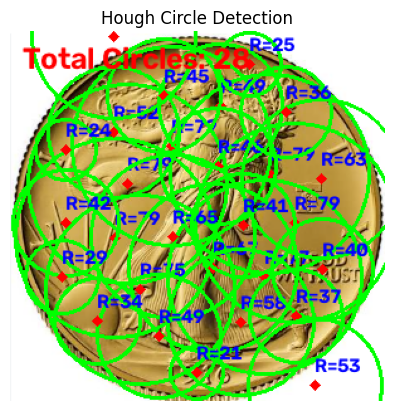

In [ ]:
#question 1
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load the coin image
coins = cv2.imread('coin.png')

# Convert to grayscale and reduce noise
gray_coins = cv2.cvtColor(coins, cv2.COLOR_BGR2GRAY)
gray_coins = cv2.medianBlur(gray_coins, 5)

# Detect circles using the Hough Circle Transform
circles_coins = cv2.HoughCircles(
    gray_coins,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=40,
    param1=100,
    param2=30,
    minRadius=15,
    maxRadius=80
)

# Make a copy of the original image
output = coins.copy()

# Count and draw detected circles
count = 0

if circles_coins is not None:
    circles_coins = np.uint16(np.around(circles_coins))

    for x, y, r in circles_coins[0, :]:
        count += 1

        # Draw the circle
        cv2.circle(output, (x, y), r, (0, 255, 0), 2)

        # Mark the center
        cv2.circle(output, (x, y), 2, (0, 0, 255), 3)

        # Label the radius
        cv2.putText(
            output,
            'R=' + str(r),
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

# Display total number of circles
cv2.putText(
    output,
    'Total Circles: ' + str(count),
    (10, 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 255),
    2
)

print("Total circles detected:", count)

# Display the result
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Hough Circle Detection")
plt.axis('off')
plt.show()

Total circles detected after tuning: 11


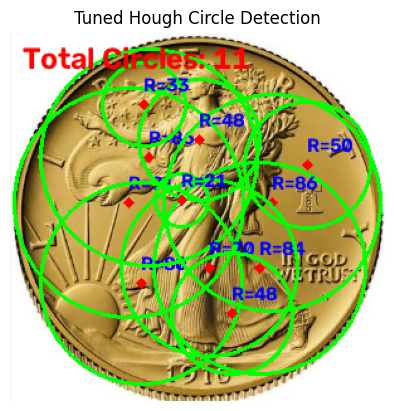

In [ ]:

# Tune circle-detection parameters
tuned_circles = cv2.HoughCircles(
    gray_coins,
    cv2.HOUGH_GRADIENT,
    dp=0.8,
    minDist=40,
    param1=150,
    param2=40,
    minRadius=10,
    maxRadius=100
)

output_tuned = coins.copy()
tuned_count = 0

if tuned_circles is not None:
    tuned_circles = np.uint16(np.around(tuned_circles))

    for x, y, r in tuned_circles[0, :]:
        tuned_count += 1

        cv2.circle(output_tuned, (x, y), r, (0, 255, 0), 2)
        cv2.circle(output_tuned, (x, y), 2, (0, 0, 255), 3)

        cv2.putText(
            output_tuned,
            'R=' + str(r),
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

cv2.putText(
    output_tuned,
    'Total Circles: ' + str(tuned_count),
    (10, 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 255),
    2
)

print("Total circles detected after tuning:", tuned_count)

plt.imshow(cv2.cvtColor(output_tuned, cv2.COLOR_BGR2RGB))
plt.title("Tuned Hough Circle Detection")
plt.axis('off')
plt.show()

Total standard Hough lines: 208
Total probabilistic line segments: 44


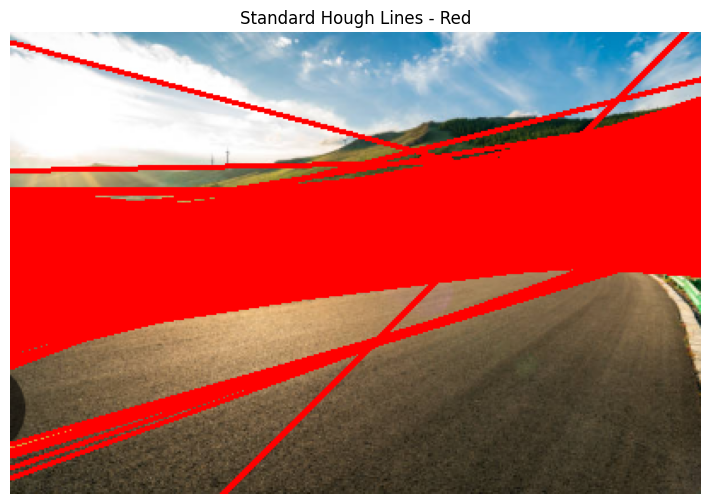

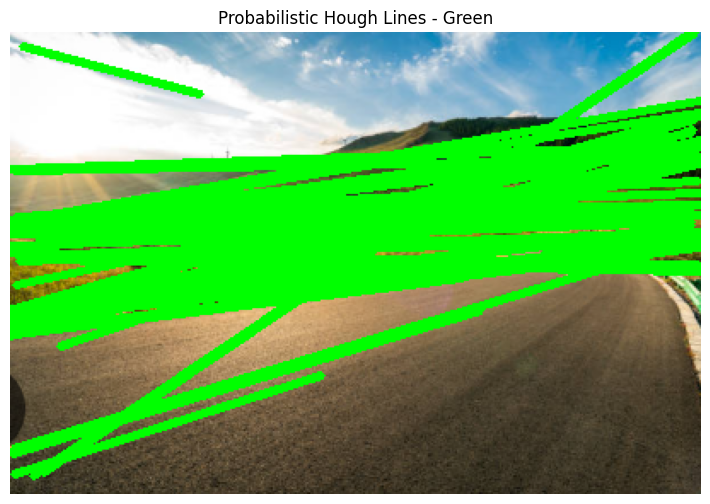

In [ ]:
#question 2

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load the road image
road = cv2.imread('road2.png')

# Convert to grayscale
gray_road = cv2.cvtColor(road, cv2.COLOR_BGR2GRAY)

# Detect edges using Canny
edges_road = cv2.Canny(gray_road, 50, 150)

# Make separate copies of the road image
road_standard = road.copy()
road_probabilistic = road.copy()

# Standard Hough Line Transform
lines_standard = cv2.HoughLines(
    edges_road,
    1,
    np.pi / 180,
    150
)

# Count standard Hough lines
if lines_standard is not None:
    standard_count = len(lines_standard)

    for rho, theta in lines_standard[:, 0]:
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        # Draw standard lines in red
        cv2.line(
            road_standard,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            2
        )
else:
    standard_count = 0

print("Total standard Hough lines:", standard_count)

# Probabilistic Hough Line Transform
lines_prob = cv2.HoughLinesP(
    edges_road,
    1,
    np.pi / 180,
    threshold=100,
    minLineLength=50,
    maxLineGap=50
)

# Count probabilistic line segments
if lines_prob is not None:
    lines_prob = lines_prob.reshape(-1, 4)
    probabilistic_count = len(lines_prob)

    for x1, y1, x2, y2 in lines_prob:
        # Draw line segments in green
        cv2.line(
            road_probabilistic,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )
else:
    probabilistic_count = 0

print("Total probabilistic line segments:", probabilistic_count)

# Display standard Hough lines
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(road_standard, cv2.COLOR_BGR2RGB))
plt.title("Standard Hough Lines - Red")
plt.axis('off')
plt.show()

# Display probabilistic Hough line segments
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(road_probabilistic, cv2.COLOR_BGR2RGB))
plt.title("Probabilistic Hough Lines - Green")
plt.axis('off')
plt.show()